<a href="https://colab.research.google.com/github/jfbadarom/Fisica-com-Python/blob/main/Tarefa_4_Joao_Felipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Parte 1

 Vá na tabela do slide 36 dessa [apresentação](https://https://docs.google.com/presentation/d/1Cbj5JP3zd2teq8xfyt7Li24cBLYrC5tI2MuddnAfN9w/edit?usp=sharing) e **escolha 2 mapas caóticos** onde você terá que fazer uma simulação para comparar com os resultados analíticos do expoente de Lyapunov e densidade invariante

Para realizar essa tarefa primeiramente vou definir uma função para descrever dois mapas de escolha.

In [2]:
import numpy as np
import matplotlib.pyplot as plt


In [3]:

def cuspide(x):
  return (1-2*np.sqrt(np.abs(x)))

def gauss(x):
  return np.mod(1/x,1) #O número que estiver depois da vírgula de 1/x. Ex: 1/x =3.27, gauss(x)=0.27

Para calcular os expoentes de Lyapunov precisamos das derivadas de ambos os mapas.

In [4]:
def dgauss(x):
  return 1/(x)**2
def dcuspide(x):
  return -np.sign(x)/(np.sqrt(np.abs(x)))

Precisamos escolher um valor inicial para x

In [5]:
x_0=0.9#Os domínios dos mapas escolhidos são diferentes mas esse valor de condicção inicial é válido para ambos
tr=10000#Transiente
N=1000000
eps=1e-10#Um termo de ajuste para até quão próximo mo mapa gaussiano vai de 0, lembrando que 0 está fora do domínio

In [6]:
x=x_0
for i in range(tr):
  x=gauss(x+eps)

In [7]:
xl=[]
dxl=[]
for i in range(N):
  x=gauss(x)
  xl.append(x)
  dxl.append(abs(dgauss(x)))
lyapunovG=1/N*sum(np.log((dxl)))
print(f"Expoente de Lyapunov para o mapa Gaussiano simulado: {lyapunovG}")
print(f"Expoente de Lyapunov para o mapa Gaussiano analítico: {np.pi**2/(6*np.log(2))}")

Expoente de Lyapunov para o mapa Gaussiano simulado: 2.3714325493992785
Expoente de Lyapunov para o mapa Gaussiano analítico: 2.373138220831251


O expoente muito próximo do valor teórico ≈2.37.

Agora vamos comparar a densidade invariante com distribuição do mapa gaussiano.

In [8]:
def densgauss(x):
  return (1/(np.log(2)*(1+x)))

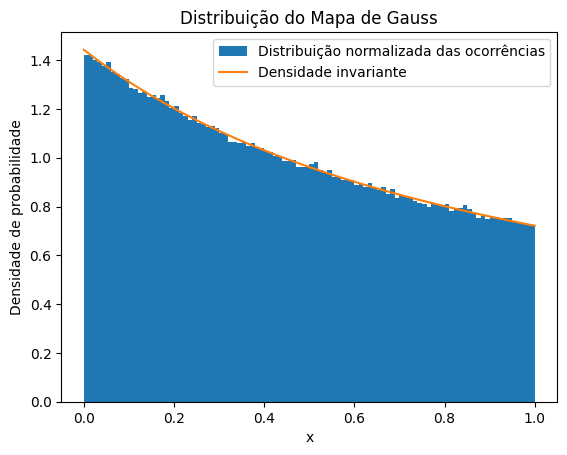

In [9]:
plt.hist(xl,bins=100,density=True, label="Distribuição normalizada das ocorrências")
dom=np.linspace(0+eps,1,1000)
plt.plot(dom,densgauss(dom),label="Densidade invariante")
plt.legend()
plt.xlabel("x")
plt.ylabel("Densidade de probabilidade")
plt.title("Distribuição do Mapa de Gauss")
plt.show()

A curva claramente faz uma envoltória na distribuição encontrada.

Vamos fazer a mesma coisa para o mapa de Cuspide

In [10]:
x_0=0.3#Os domínios dos mapas escolhidos são diferentes mas esse valor de condicção inicial é válido para ambos
tr=10000#Transiente
N=1000000

In [11]:
x=x_0
for i in range(tr):
  x=cuspide(x)

In [12]:
xl=[]
dxl=[]
for i in range(N):
  x=cuspide(x)
  xl.append(x)
  dxl.append(abs(dcuspide(x)))
lyapunovC=1/N*sum(np.log(dxl))
print(f"Expoente de Lyapunov para o mapa Gaussiano simulado: {lyapunovC}")
print(f"Expoente de Lyapunov para o mapa Gaussiano analítico: {1/2}")

Expoente de Lyapunov para o mapa Gaussiano simulado: 0.49999707325193377
Expoente de Lyapunov para o mapa Gaussiano analítico: 0.5


In [13]:
def denscuspide(x):
  return 1/2*(1-x)

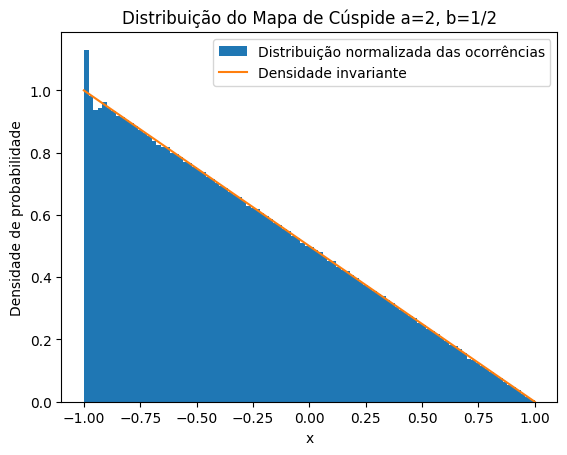

In [14]:
plt.hist(xl,bins=100,density=True, label="Distribuição normalizada das ocorrências")
dom=np.linspace(-1,1,1000)
plt.plot(dom,denscuspide(dom),label="Densidade invariante")
plt.legend()
plt.xlabel("x")
plt.ylabel("Densidade de probabilidade")
plt.title("Distribuição do Mapa de Cúspide a=2, b=1/2")
plt.show()

A Densidade invariante também se torna a envoltória da distribuição

>>>> Logistic map

Sobre o artigo abaixo: use a Eq.5 para obter computacionalmente os resultados equivalentes aos experimentais mostrados na Fig.(5,7)

* Suneel, Madhekar. "Electronic circuit realization of the logistic map." Sadhana (2006). [LINK](https://www.ias.ac.in/public/Volumes/sadh/031/01/0069-0078.pdf)


In [15]:
def logistic(x,r):
  return r*x*(10-x)/25

In [22]:
x_0=0.5
tr=100#Transiente
N=1000

Precisamos para recuperar os resultados dos gráficos varrer vários valores de r possíveis.

In [23]:

x=x_0
r=np.linspace(2,10,10000)
xl=[]
for i in range(tr):
  x=logistic(x,r)


Descartando o transiente, podemos agora evoluir o sistema e fazer o plot.

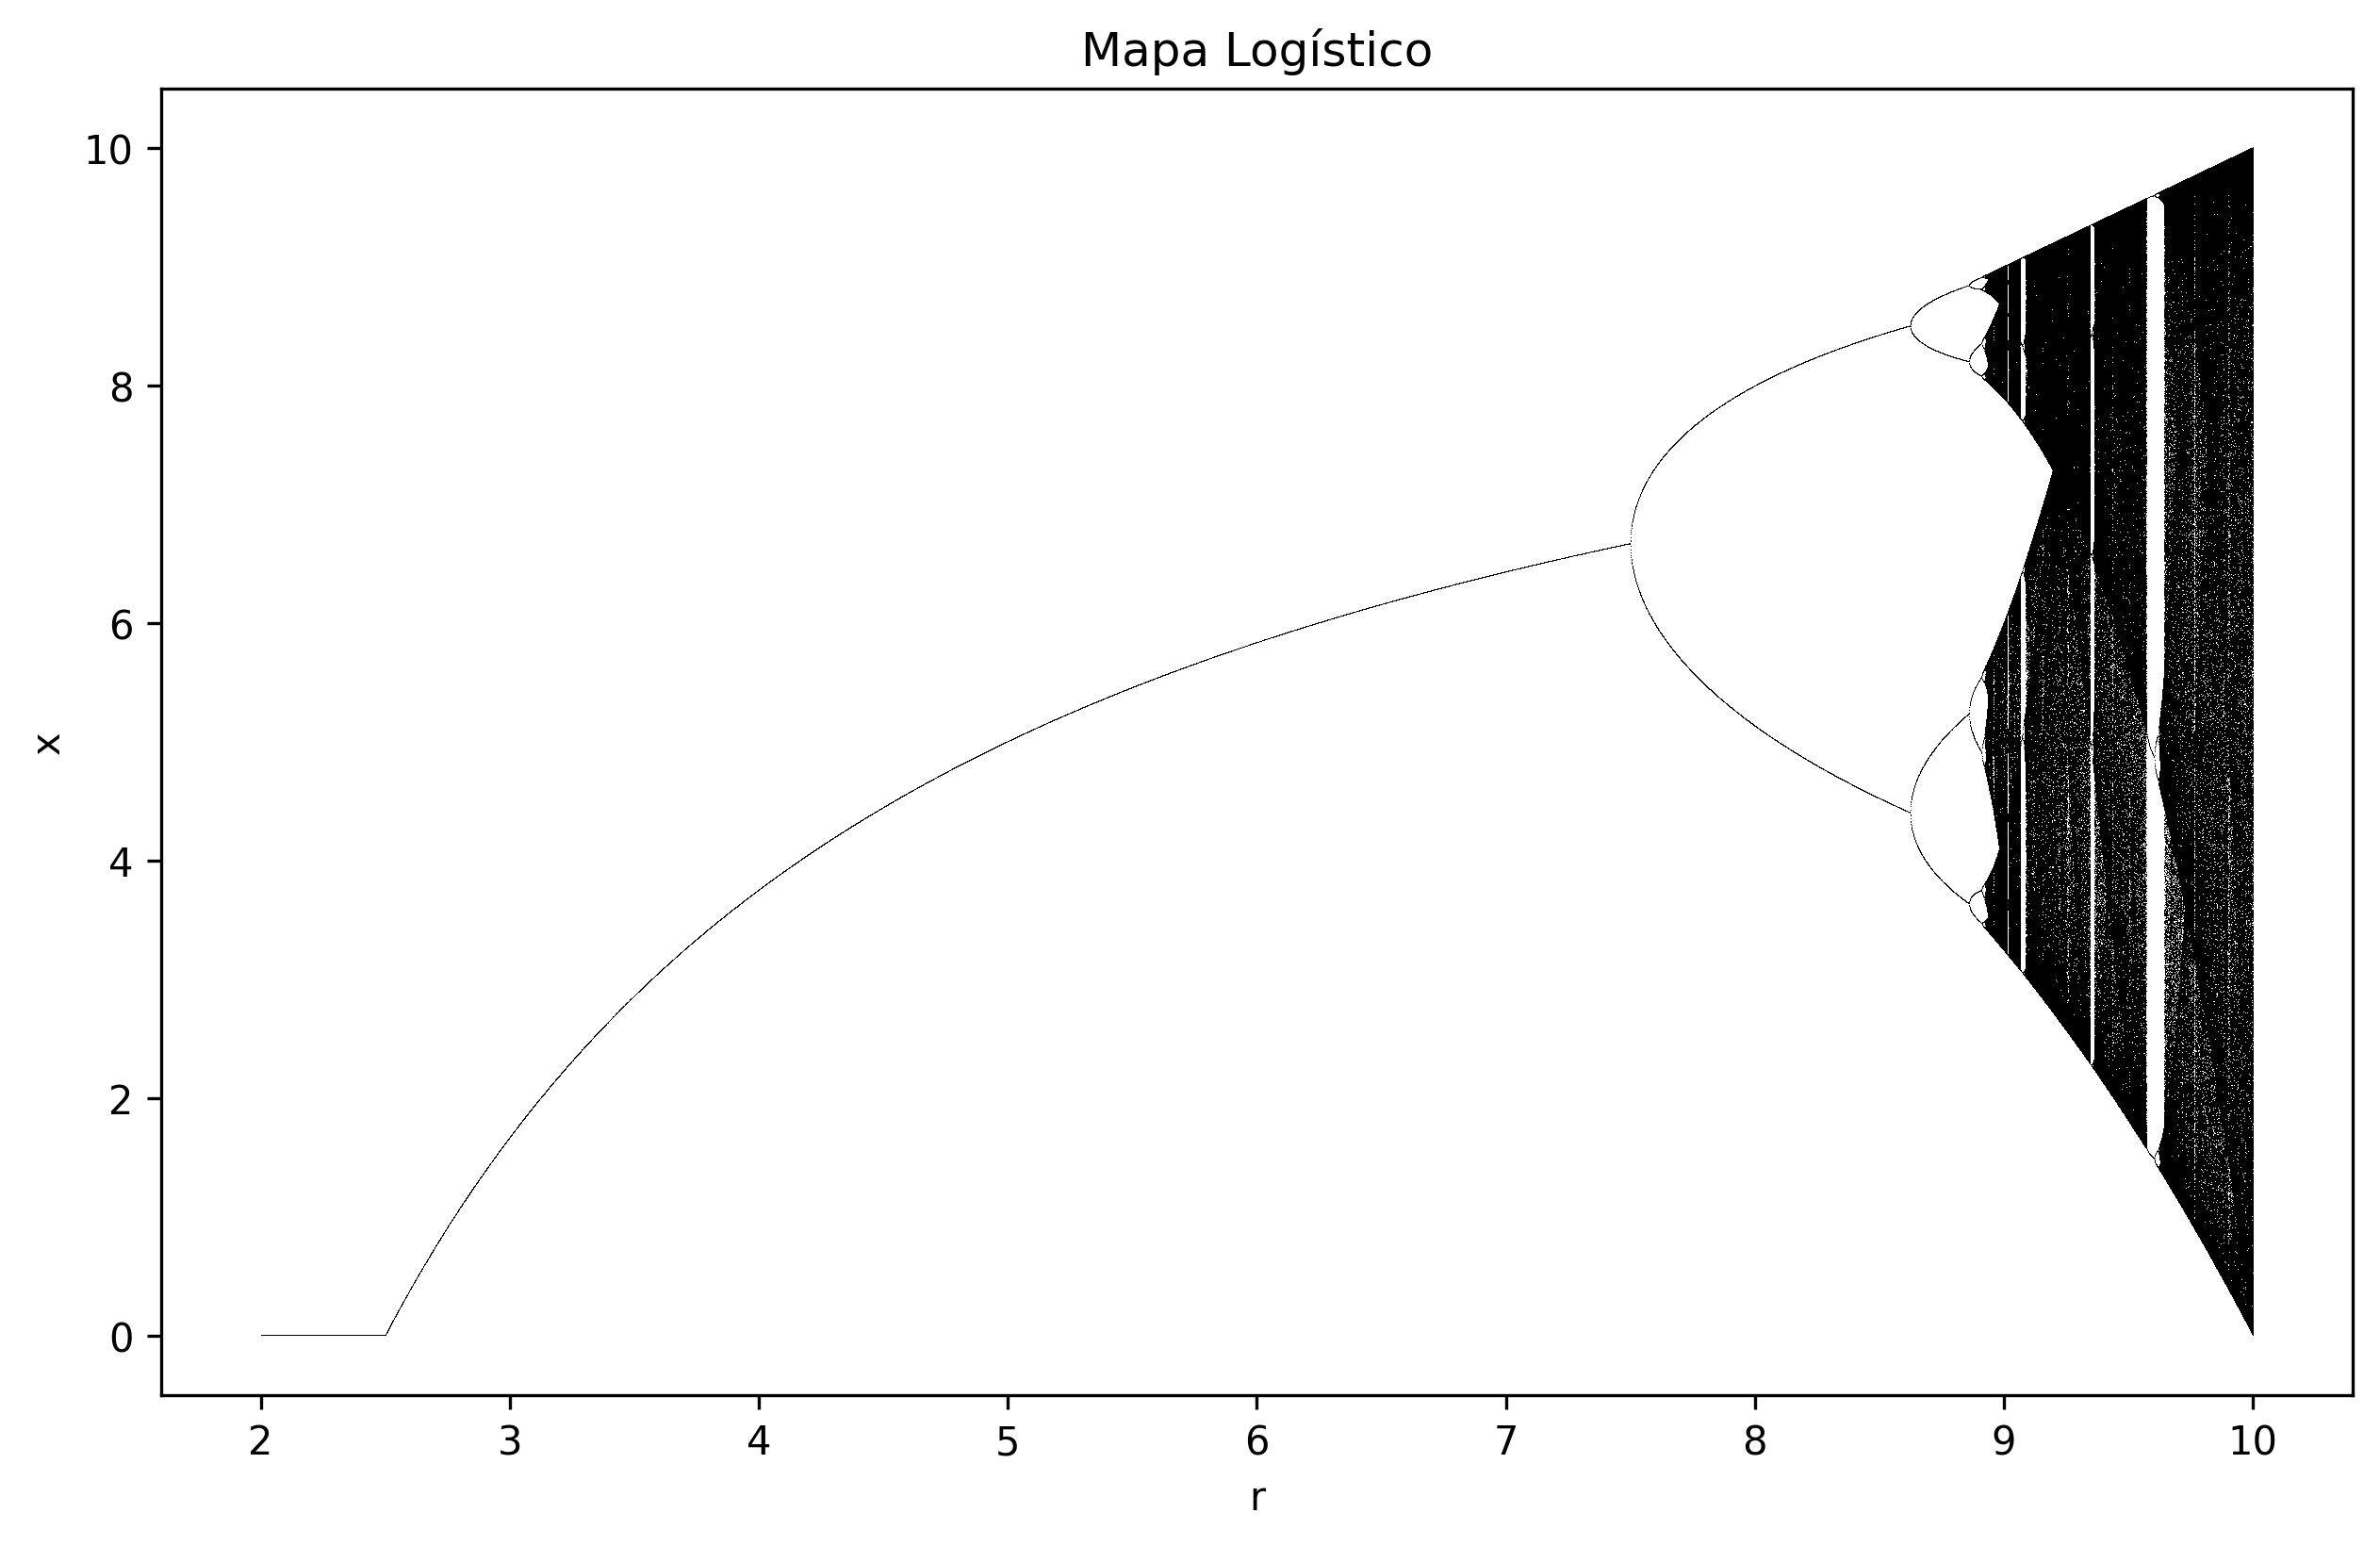

In [34]:
xl=[]
plt.figure(dpi=300, figsize=(10,6))
for i in range(N):
  x=logistic(x,r)
  xl.append(x)
  plt.plot(r, xl[i], ',', color='black')
plt.xlabel("r")
plt.ylabel("x")
plt.title("Mapa Logístico")

plt.show()

Agora para dar um zoom na parte final do gráfico.

(7.65, 10.0)

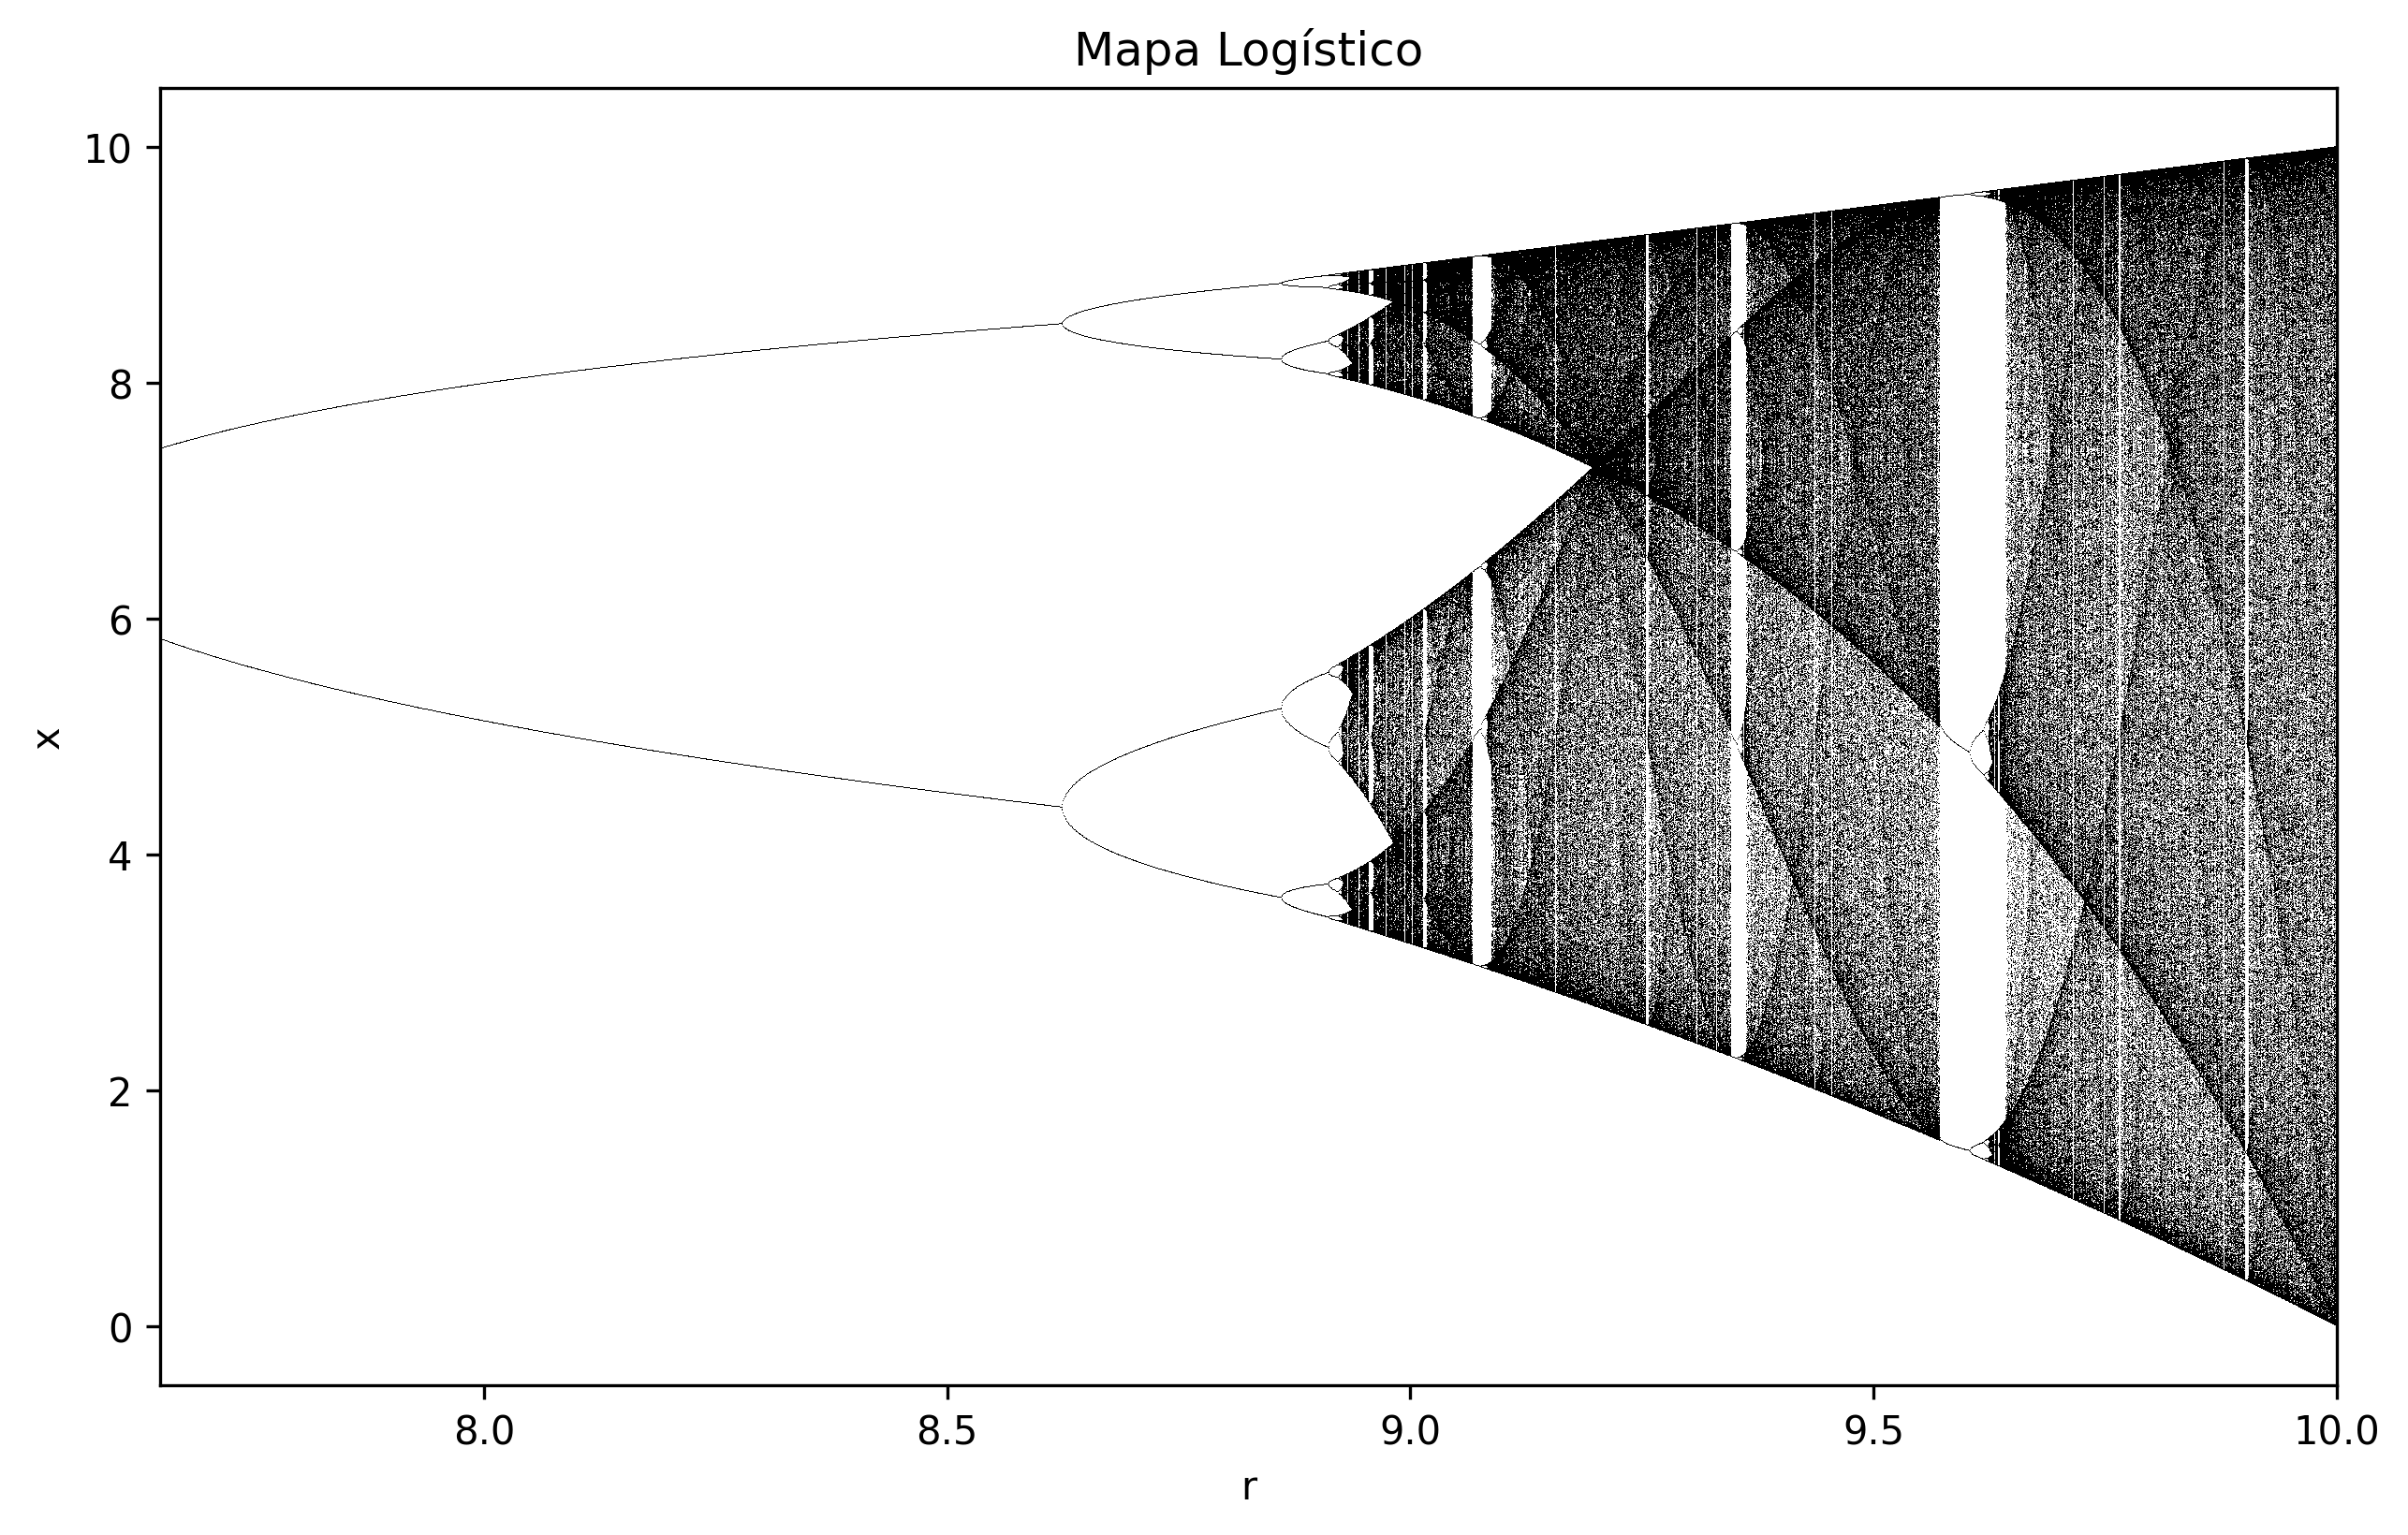

In [35]:

plt.figure(dpi=300, figsize=(10,6))
for i in range(N):
  plt.plot(r, xl[i], ',', color='black')
plt.xlabel("r")
plt.ylabel("x")
plt.title("Mapa Logístico")
plt.xlim(7.65,10)


>>>> Cossenoidal map

Sobre o artigo abaixo: use a Eq.5 para reproduzir a Fig.4. Compare com o correspondente resultado experimental na Fig.3.

* Artigo: Ma, Yu-Han, et al. "Experimental system of coupled map lattices." Frontiers of Physics (2015) [LINK](https://www.researchgate.net/profile/Yu-Han-Ma/publication/277567812_Experimental_system_of_coupled_map_lattices/links/59e40e4aaca2724cbfe3bb01/Experimental-system-of-coupled-map-lattices.pdf)


Vamos definir o mapa cosseinodal.

In [111]:
def cossenoidal(x,k):
  return k/2*(1+np.cos(2*np.pi*x))

In [118]:
x_0=0.5
tr=1000#Transiente
N=10000

In [119]:

x=x_0
k=np.linspace(0,1,1000)
xl=[]
for i in range(tr):
  x=cossenoidal(x,k)

E da mesma forma que fizemos anteriormente para o mapa logístico fazemos para o plot.

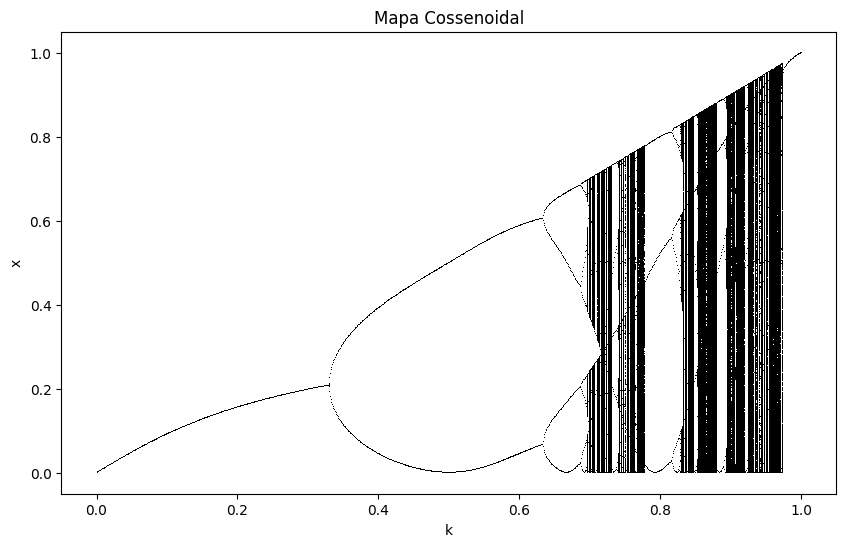

In [120]:
xl=[]
plt.figure(dpi=100, figsize=(10,6))
for i in range(N):
  x=cossenoidal(x,k)
  xl.append(x)
  plt.plot(k, xl[i], ',', color='black')
plt.xlabel("k")
plt.ylabel("x")
plt.title("Mapa Cossenoidal")

plt.show()

Para o verificar a evolução do expoente de Lyapunov vamos precisar de definir a derivada do mapa cossenoidal.

In [121]:
def dcossenoidal(x,k):
  return -k*np.pi*np.sin(2*np.pi*x)


Assim precisamos apenas verificar o valor da função da derivada nos pontos x que já obtemos e calcular portanto o expoente de Lyapunov.

/tmp/ipykernel_7377/387305298.py:8: RuntimeWarning: divide by zero encountered in log
  plt.plot(k, 1/N*sum(np.log(dxl)), color='black')


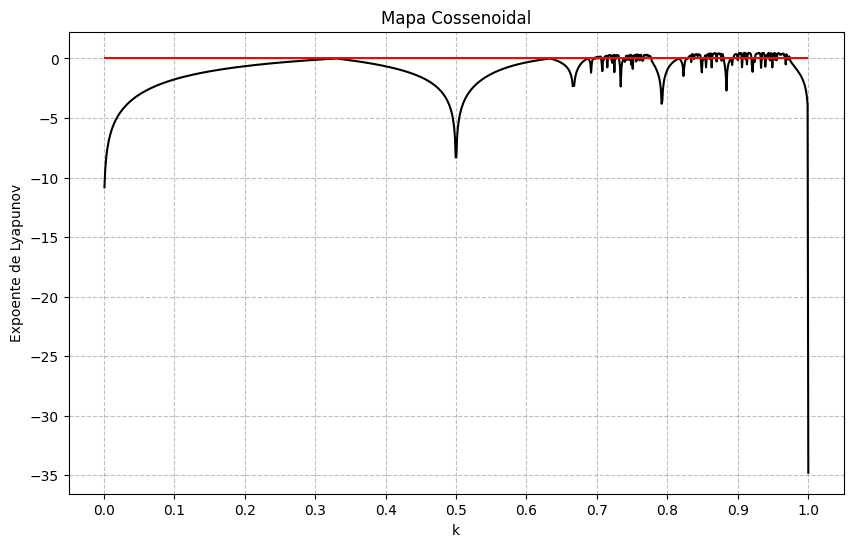

In [127]:
plt.figure(dpi=100, figsize=(10,6))
dxl=[]
dx=0
for i in range(N):
  dx=abs(dcossenoidal(xl[i],k))
  dxl.append(dx)

plt.plot(k, 1/N*sum(np.log(dxl)), color='black')
plt.xlabel("k")
plt.ylabel("Expoente de Lyapunov")
plt.title("Mapa Cossenoidal")
ticks = np.linspace(0.0, 1.0, 11)

plt.xticks(ticks)
plt.grid(True, linestyle="--", alpha=0.5, color="gray")
plt.hlines(y=0, xmin=0, xmax=1, color="r")
plt.show()